## 04 Modeling Population and Split

#### Purpose
- We define the modeling population for each of our two models, **claim** and **lapse**: the policy-years each model is trained and tested on.
- Our lapse target combines a lapse cancellation during the year and a non-renewal at its end (`LAPSE`).
- We split them by time into train, validation and test sets, and set up rolling-origin folds.

#### Steps:
- Check the data limits (years, storm years, censoring)
- Define the modeling scope (states and years)
- Exclusions and row-count waterfall, per target
- Sampling strategy
- Time-based train, validation and test split
- Rolling-origin folds
- Check sizes and target rates per split
- Export the population and split assignments

#### Inputs and outputs
- **In:** `data/processed/periods/<state>.parquet` (notebook 03), `data/processed/policies_clean/` and `claims_clean.parquet` (notebook 02).
- **Out:** `data/processed/modeling_population.parquet` (one row per policy-year in any population, with split, sample and weight columns), waterfall and split reports in `reports/`, `docs/population_decisions.md`.

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-12

### Section 0. Setup

#### 0.1 Imports and paths
We use the same setup as notebooks 02 and 03. The functions for this notebook live in `src/population.py`; we read their documentation with `help(function_name)`.

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.paths import DOCS, INTERIM, PROCESSED, REPORTS, ensure_dirs
from src.db import RAW_FILES, connect, scalar
from src.dq import CleaningLog
from src.population import (LAPSE_SQL, TARGETS, all_of, rolling_folds, sample_condition, split_case,
                            split_summary_sql, waterfall_frame, waterfall_sql)

ensure_dirs()

#### 0.2 Connection and decisions
We set every decision of this notebook here, in one place. The values below are **proposals**: we confirm or change each one after reading the section named in its comment, then rerun from Section 3.

| Decision | Proposal | Why |
|---|---|---|
| Scope | all states, policy-years starting 2014-01-01 to 2024-08-31 | The model learns many kinds of floods (hurricanes, river floods, flash floods) in every region; the window holds storm years (Matthew 2016, Harvey and Irma 2017, Florence 2018, Ida 2021, Ian 2022, Debby, Helene and Milton 2024) and calm years. 2024 ends in August, the last start month whose claim outcome is fully known (Step 2.3b) |
| Split | train 2014–2020; **test** 2021–2022, to tune and compare models; **validation** 2023 to August 2024, the final holdout used once | Each split comes after the one before it, the way the model would be used. Training includes storm years (2016–2017), tuning includes Ian (2022), and the final holdout has a calm year (2023) and a storm year (2024) |
| Multi-unit rows | excluded | One row covers many condo units, so it is not one policyholder's decision |
| Lapse target | `LAPSE` = 1 if cancelled for a lapse reason during the year (`CANCEL_IN_TERM`) or not renewed at the end (`NON_RENEWAL`) | One lapse model, as planned in our README: both are a policyholder leaving |
| Key collisions | excluded from both populations | Their claims and renewals may belong to another house |
| Rewrite or sale | the policy-year it ended is excluded from the lapse population | Neither a lapse nor a normal continuation |
| Sampling | none (`NEG_RATE` = 1.0) | We keep every policy-year, so no weights are needed. The training split is large (about 29M policy-years), so notebooks 06–07 load it in compact types and train in batches (see 4.1) |

**Our naming:** we call the split we tune on **test** and the final holdout **validation**. Many ML texts use the opposite names, so we state it here; in the code, `TUNING_SPLIT` and `HOLDOUT_SPLIT` say which is which.

In [2]:
con = connect(db_path=INTERIM / "nfip_04.duckdb", memory_limit="10GB")   # own file: no lock clash with other notebooks
con.execute("SET TimeZone = 'UTC'")

SCOPE_STATES = sorted(p.stem for p in (PROCESSED / "periods").glob("*.parquet"))   # Section 3.1: every state built in notebook 03
YEARS = (2014, 2024)                                    # first and last policy-year start (Section 2.3)
LAST_START = "2024-08-31"                               # Section 2.3b: last start date with every claim outcome known
SPLIT_YEARS = {"train": list(range(2014, 2021)),        # 2014-2020: includes the 2016-2017 storms
               "test": [2021, 2022],                     # tune and compare models (Ian 2022)
               "valid": [2023, 2024]}                    # final holdout: 2023 (calm) and Jan-Aug 2024 (Debby, Helene, Milton)
TUNING_SPLIT = "test"       # our name for the split we tune and compare models on
HOLDOUT_SPLIT = "valid"     # our name for the final holdout, used once at the end

EXCLUDE_MULTI_UNIT = True                               # Section 3.2: policyCount > 1
DQ_EXCLUDE = ["dq_term_end_before_start", "dq_effective_in_future", "dq_cancel_after_termination"]   # Section 3.2
EXCLUDE_OCCUPANCY = []                                  # Section 3.2: we keep every occupancy
EXCLUDE_COLLISIONS = True                               # both populations (claims and renewals need the key)
LAPSE_EXCLUDE_CATEGORIES = ["rewrite", "sold_removed"]  # cancellation categories that end a term without a lapse

NEG_RATE = {"claim": 1.0, "lapse": 1.0}      # Section 4.1: 1.0 = no sampling (our decision: we keep every row)
SEED = 42

log = CleaningLog()

# The split must cover the scope years exactly, once each
split_years = sorted(y for ys in SPLIT_YEARS.values() for y in ys)
assert split_years == list(range(YEARS[0], YEARS[1] + 1)), f"SPLIT_YEARS {split_years} does not match YEARS {YEARS}"

### Section 1. Load the labeled table

#### 1.1 Load the policy-years from notebook 03
We create views over the labeled policy-years (all states), the clean policies (for the `dq_` flags and occupancy) and the clean claims.

In [3]:
# Step 1.1a Views
PERIODS_DIR = PROCESSED / "periods"
con.execute(f"CREATE OR REPLACE VIEW periods_all AS SELECT * FROM read_parquet('{PERIODS_DIR}/*.parquet')")
con.execute(f'''CREATE OR REPLACE VIEW clean_policies AS
                SELECT * FROM read_parquet('{PROCESSED / "policies_clean"}/**/*.parquet', hive_partitioning = true)''')
con.execute(f"CREATE OR REPLACE VIEW clean_claims AS SELECT * FROM read_parquet('{PROCESSED / 'claims_clean.parquet'}')")

# Every state with policies must have a notebook 03 output, or the population would silently miss it
expected = [r[0] for r in con.execute(
    "SELECT DISTINCT propertyState FROM clean_policies WHERE propertyState IS NOT NULL ORDER BY 1").fetchall()]
missing = sorted(set(expected) - set(SCOPE_STATES))
assert not missing, f"no notebook 03 output for {missing}: finish notebook 03 Section 9 first"
print(len(SCOPE_STATES), "states in scope")

57 states in scope


In [4]:
# Step 1.1b Row counts and target columns
targets = ["CLAIM_IN_TERM", "CLAIM_PAID_IN_TERM", "CANCEL_IN_TERM", "SOLD_REMOVED_IN_TERM", "NON_RENEWAL"]
con.sql(f'''
    SELECT COUNT(*) AS policy_years,
           COUNT(*) FILTER (WHERE period_no = 0) AS terms,
           {", ".join(f"COUNT({t}) AS {t}_labeled, ROUND(100 * AVG({t}), 3) AS {t}_pct" for t in targets)}
    FROM periods_all
''').df().T

,0
policy_years,7.324830e+07
terms,7.310863e+07
CLAIM_IN_TERM_labeled,6.581324e+07
CLAIM_IN_TERM_pct,1.352000e+00
CLAIM_PAID_IN_TERM_labeled,6.581324e+07
CLAIM_PAID_IN_TERM_pct,1.121000e+00
CANCEL_IN_TERM_labeled,6.986788e+07
CANCEL_IN_TERM_pct,1.640000e-01
SOLD_REMOVED_IN_TERM_labeled,6.986788e+07
SOLD_REMOVED_IN_TERM_pct,2.218000e+00


### Section 2. Check the data limits
We choose the years from what the data allows, not from assumptions.

#### 2.1 Policy-years per year and state
We find the first and last years with policy-years, and how large each state is.

In [5]:
# Step 2.1a Policy-years per start year: all states and the largest states
by_state_year = con.sql('''
    SELECT propertyState, 
           period_year, 
           COUNT(*) AS n
    FROM periods_all 
    GROUP BY ALL
''').df()
top_states = by_state_year.groupby("propertyState")["n"].sum().nlargest(6).index
table = by_state_year.pivot(index="period_year", columns="propertyState", values="n").fillna(0).astype(int)
table.insert(0, "ALL", table.sum(axis=1))
table[["ALL", *top_states]]

propertyState,ALL,FL,TX,LA,CA,NJ,SC
period_year,,,,,,,
2009,4599725,1468936,657235,476236,263641,174123,146229
2010,4559936,1431779,647616,475418,256590,174894,147509
2011,4589510,1404360,637700,485372,253150,178269,149577
2012,4562275,1405275,625484,478260,247608,182793,152006
2013,4527567,1392033,608993,474653,237608,188889,155014
2014,4379779,1348547,584375,465900,226191,184854,154095
2015,4209780,1222880,571829,446891,280701,179416,153242
2016,4130705,1181529,588924,488728,242432,172581,154740
2017,4168022,1192053,647011,494718,232652,167930,159010


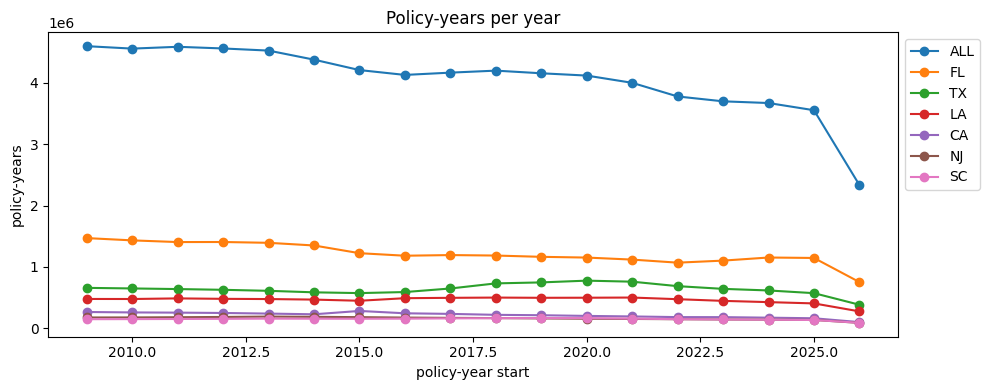

In [6]:
# Step 2.1b Chart
ax = table[["ALL", *top_states]].plot(figsize=(10, 4), marker="o")
ax.set(xlabel="policy-year start", ylabel="policy-years", title="Policy-years per year")
ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(REPORTS / "fig_policy_years_by_year.png", dpi=150)
plt.show()

#### 2.2 Claims per loss year
We find the storm years that drive claims, nationally and in the scope states.

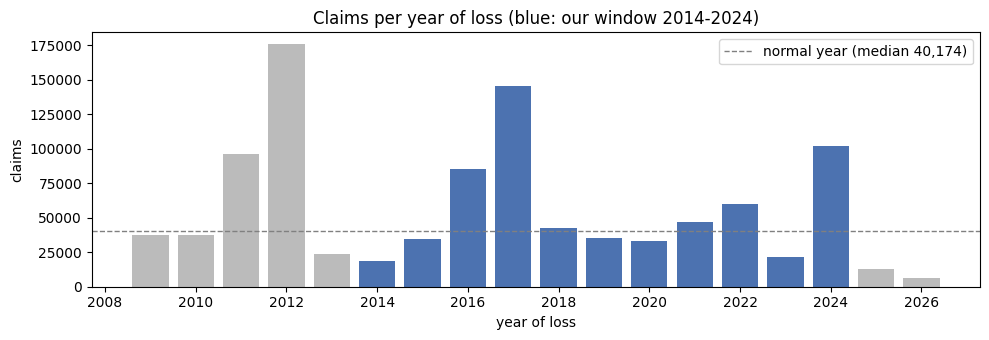

normal year (median claims): 40,174


,loss_year,claims,x_normal_year,share_of_window_pct
3,2012,175556,4.4,NaN
8,2017,145193,3.6,23.2
15,2024,101897,2.5,16.3
2,2011,96322,2.4,NaN
7,2016,85357,2.1,13.7
13,2022,60071,1.5,9.6
12,2021,46642,1.2,7.5
9,2018,42610,1.1,6.8
1,2010,37738,0.9,NaN
0,2009,37653,0.9,NaN


In [7]:
# Step 2.2 Claims per year of loss: which years drive the claims?
claims_year = con.sql('''
    SELECT YEAR(loss_date) AS loss_year, COUNT(*) AS claims
    FROM clean_claims
    WHERE loss_date >= DATE '2009-01-01'
    GROUP BY 1 ORDER BY 1
''').df()

normal = claims_year.loc[claims_year["loss_year"] <= 2024, "claims"].median()   # leave out the incomplete last years
in_window = claims_year["loss_year"].between(*YEARS)
claims_year["x_normal_year"] = (claims_year["claims"] / normal).round(1)
claims_year["share_of_window_pct"] = (100 * claims_year["claims"]
                                      / claims_year.loc[in_window, "claims"].sum()).where(in_window).round(1)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(claims_year["loss_year"], claims_year["claims"],
       color=["#4C72B0" if w else "#BBBBBB" for w in in_window])
ax.axhline(normal, color="grey", linestyle="--", linewidth=1, label=f"normal year (median {normal:,.0f})")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set(xlabel="year of loss", ylabel="claims", title=f"Claims per year of loss (blue: our window {YEARS[0]}-{YEARS[1]})")
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / "fig_claims_by_loss_year.png", dpi=150)
plt.show()

print("normal year (median claims):", f"{normal:,.0f}")
claims_year.sort_values("claims", ascending=False)

> **Our findings:**
>
> - **A few storm years drive most claims.** A normal year has about 38,000 claims (median). The largest years are 2012 (175,556, 4.7× normal, Sandy), 2017 (145,193, 3.9×, Harvey, Irma and Maria), 2024 (101,897, 2.7×, Debby, Helene and Milton), 2011 (96,322, 2.6×, Irene) and 2016 (85,357, 2.3×, the Louisiana floods and Matthew).
> - **Our window (2014–2023) contains both storm and calm years.** Of its 523,242 claims, 2017 alone gives 28% and 2016–2017 together 44%. Both are in our training years (2014–2020), so the model learns from large storms. The test years contain Ian (2022, 1.6×) and a calm year (2023).
> - **2025 and 2026 look low because they are incomplete:** 2026 ends at the cutoff (2026-09-08), and recent claims are still being reported.
> - **What it means for us:** the claim rate depends on whether a storm hits, not only on the policy. We need the disaster and weather features in notebook 05, and we read model results year by year, not only as one average.

#### 2.3 Data cutoff and label maturity
The last usable policy-year must end early enough for its outcome to be observed. In notebook 03, we set every target that can't be observed yet to NULL. Here we see, per year, how much of each target is labeled.

Step 2.3b looks inside 2024 month by month, to find the last start month whose claim outcome is fully known.

In [8]:
# Step 2.3 Cutoff, and the share of policy-years with a known outcome, per year (scope states)
CUTOFF = pd.Timestamp(scalar(con, f"SELECT CAST(MAX(asOfDate) AS DATE) FROM read_parquet('{RAW_FILES['raw_policies']}')")).date()
print("CUTOFF =", CUTOFF)

maturity = con.sql(f'''
    SELECT period_year,
           COUNT(*) AS policy_years,
           ROUND(100 * AVG(CAST(CLAIM_IN_TERM IS NOT NULL AS INTEGER)), 1)  AS claim_labeled_pct,
           ROUND(100 * AVG(CAST(CANCEL_IN_TERM IS NOT NULL AS INTEGER)), 1) AS cancel_labeled_pct,
           ROUND(100 * AVG(CAST(NON_RENEWAL IS NOT NULL AS INTEGER)) FILTER (WHERE is_last_period), 1) AS non_renewal_labeled_pct,
           ROUND(100 * AVG(CAST(({LAPSE_SQL}) IS NOT NULL AS INTEGER)), 1) AS lapse_labeled_pct
    FROM periods_all
    WHERE propertyState IN ({", ".join(f"'{s}'" for s in SCOPE_STATES)})
    GROUP BY 1 ORDER BY 1
''').df()
maturity

CUTOFF = 2026-09-08


,period_year,policy_years,claim_labeled_pct,cancel_labeled_pct,non_renewal_labeled_pct,lapse_labeled_pct
0,2009,4599725,99.3,100.0,99.4,99.3
1,2010,4559936,99.3,100.0,99.4,99.3
2,2011,4589510,99.3,100.0,99.4,99.3
3,2012,4562275,99.4,100.0,99.5,99.4
4,2013,4527567,99.3,100.0,99.5,99.3
5,2014,4379779,99.4,100.0,99.6,99.4
6,2015,4209780,99.5,100.0,99.5,99.5
7,2016,4130705,99.4,100.0,99.7,99.4
8,2017,4168022,99.3,100.0,99.7,99.3
9,2018,4200679,99.1,100.0,99.5,99.1


> **Our findings:**
>
> - **The cutoff is 2026-09-08**, the latest `asOfDate` in the policies file. Anything after it is unknown.
> - **All three targets are fully labeled up to 2023.** For policy-years starting 2014–2023, 99.1–99.5% have a claim label, 100% a cancellation label and about 99.4% a renewal label. The missing ~0.6% are policy-years whose key is incomplete (Section 3 of notebook 03), not censoring, so they do not depend on the year.
> - **2024 is not mature for claims.** Only 69.2% of the 2024 policy-years have a claim label: our 365-day claim delay censors every policy-year ending after 2025-09-08, so only those starting early in 2024 are labeled. Cancellation is fully labeled in 2024 (100%), and non-renewal 99.8%.
> - **2025 and 2026 are mostly unknown** (claims 0.5% and 0%, cancellations 70.2% and 0.5%). As notebook 03 Step 10.4 showed, the few labeled rows in these years are the policies that already left, so their rates are biased upward.
> - **Our choice: we extend `YEARS` to 2024**, using only the policy-years whose claim outcome is fully known (Step 2.3b), so our final holdout gets a storm year (Debby, Helene, Milton) next to the calm 2023.

In [9]:
# Step 2.3b 2024 by start month: from which month is the claim outcome no longer fully known?
con.sql(f'''
    SELECT month(period_start) AS start_month,
           COUNT(*) AS policy_years,
           ROUND(100 * AVG(CAST(CLAIM_IN_TERM IS NOT NULL AS INTEGER)), 1)                         AS claim_labeled_pct,
           ROUND(100 * AVG(CAST(({LAPSE_SQL}) IS NOT NULL AS INTEGER)), 1)                         AS lapse_labeled_pct,
           ROUND(100 * AVG(CAST(key_complete AS INTEGER)), 1)                                     AS key_complete_pct
    FROM periods_all
    WHERE period_year = 2024
    GROUP BY 1 ORDER BY 1
''').df()

,start_month,policy_years,claim_labeled_pct,lapse_labeled_pct,key_complete_pct
0,1,204251,99.5,99.5,99.5
1,2,220009,99.5,99.5,99.5
2,3,270318,99.4,99.5,99.4
3,4,280320,99.6,99.6,99.6
4,5,319296,99.7,99.7,99.7
5,6,384919,99.7,99.7,99.7
6,7,409125,99.9,99.9,99.9
7,8,359214,99.8,99.8,99.8
8,9,359457,24.4,99.7,99.7
9,10,343089,2.0,99.7,99.7


> **Our findings (2.3b):**
>
> - **The claim outcome of 2024 is fully known for policy-years starting January to August.** In those months the share with a claim label (99.4–99.9%) equals the share with a complete key, so the only unlabeled rows are the ones we can never link. From September it drops to 24.4%, and to about 2% for October–December: those policy-years end after 2025-09-08 (the cutoff minus our 365-day claim delay), so their claims may not be in the data yet.
> - **We cut by start date, not by "has a label".** All policy-years starting by 2024-08-31 are included, whatever happened to them. Keeping only the rows that already have a label would keep mostly the policies that ended early, the same bias we saw for 2025–2026 in notebook 03 (Step 10.4).
> - **Our choice: `LAST_START = 2024-08-31`.** This adds 2,447,452 policy-years (67% of 2024) to our final holdout. Lapse is known for all of 2024, but we use the same cut for both models so they share one holdout.
> - **What to keep in mind:** every policy-year starting January–August 2024 covers the whole 2024 hurricane season (Debby, Helene, Milton), so the claim rate of this group is higher than a calendar-year rate. It is a fair test of the model, since each row is scored against its own outcome, but we will not report it as "the 2024 claim rate".

### Section 3. Define the modeling population
Our unit is the policy-year. We apply the filters in order and record how many rows each removes, separately for each target.

#### 3.1 Scope
We keep the scope states and add the columns we filter on from the clean policies: occupancy and every `dq_` flag from notebook 02.

**Our scope:** all states, policy-years starting 2014-01-01 to 2024-08-31.
- **All states:** the model learns from every region and kind of flood, not one state's hurricanes. The state, region and flood-zone features let it tell the regions apart. Florida alone has about a third of all policy-years.
- **2014 to August 2024:** both storm years (Matthew 2016, Harvey and Irma 2017, Ian 2022, Debby, Helene and Milton 2024) and calm years. It starts after the 2014 HFIAA changes, and ends with the last start month whose claim outcome is fully known (Step 2.3b).
- **Why not 2019–2023:** the national claim rate was 0.7–1.0% in 2019–2021 but 1.3% in 2022 (Ian), and Florida's 0.3–0.9% vs 3.7%. Training only on calm years and checking on Ian would make the model learn a world without storms.
- **Risk Rating 2.0 (October 2021 for new policies, April 2022 for renewals):** all training years are rated under the old rules; the test years (2021–2022) are a mix, and the validation years (2023–2024) are mostly under the new rules. Features that exist only under Risk Rating 2.0 (`full_risk_premium`, `discount_to_full_risk`) are empty in training, and the meaning of the premium changes. We treat this as a known limit: in notebook 05 we check which price features keep the same meaning across the change, and in notebook 08 we report the validation results for 2023 and 2024 separately.

In [10]:
# Step 3.1 Base view: the scope states, with occupancy and the notebook 02 dq_ flags
pol_cols = con.sql("DESCRIBE clean_policies").df()["column_name"].tolist()
DQ_FLAGS = sorted(c for c in pol_cols if c.startswith("dq_") and c != "dq_identical_group_size")   # a count, not a flag
state_files = ", ".join(f"'{PERIODS_DIR / s}.parquet'" for s in SCOPE_STATES)
states_sql = ", ".join(f"'{s}'" for s in SCOPE_STATES)

con.execute(f'''
CREATE OR REPLACE VIEW pop_base AS
SELECT p.*,
       {LAPSE_SQL} AS LAPSE,          -- our lapse target: lapse cancellation or non-renewal
       c.occupancyType,
       {", ".join(f"c.{f}" for f in DQ_FLAGS)}
FROM read_parquet([{state_files}]) p
LEFT JOIN (
    SELECT  id, 
            occupancyType, 
            {", ".join(DQ_FLAGS)}
    FROM clean_policies
    WHERE propertyState IN ({states_sql})
      AND eff_year BETWEEN {YEARS[0] - 3} AND {YEARS[1]}     -- a 3-year term can start up to 2 years earlier
) c USING (id)
''')
print(len(DQ_FLAGS), "dq_ flags:", ", ".join(DQ_FLAGS))
scalar(con, f"SELECT COUNT(*) FROM pop_base WHERE period_year BETWEEN {YEARS[0]} AND {YEARS[1]}")

28 dq_ flags: dq_building_cov_over_limit, dq_cancel_after_termination, dq_cancel_before_effective, dq_construction_before_1800, dq_construction_in_future, dq_contents_cov_over_limit, dq_effective_before_1968, dq_effective_in_future, dq_geo_state_mismatch, dq_identical_row, dq_invalid_buildingDescriptionCode, dq_invalid_disasterAssistanceCoverageRequiredCode, dq_invalid_floodZoneCurrent, dq_invalid_foundationType, dq_invalid_policyTermIndicator, dq_latitude_out_of_range, dq_longitude_out_of_range, dq_multi_unit, dq_nb_after_effective, dq_nb_before_1968, dq_negative_building_cov, dq_negative_contents_cov, dq_negative_policy_cost, dq_negative_premium, dq_policycount_zero_or_less, dq_term_end_before_start, dq_term_longer_than_3y, dq_term_mismatch


44520167

#### 3.2 Exclusions
We look at the candidates before deciding: rows with `dq_` flags, `policyCount` > 1 (condo master policies), occupancy types, and key collisions.

In [11]:
# Step 3.2a How many scope policy-years carry each dq_ flag?
in_years = f"period_year BETWEEN {YEARS[0]} AND {YEARS[1]} AND period_start <= DATE '{LAST_START}'"   # Step 2.3b
dq_counts = con.sql(f'''
    SELECT {", ".join(f"COUNT(*) FILTER (WHERE {f}) AS {f}" for f in DQ_FLAGS + ["dq_key_collision"])},
           COUNT(*) AS total
    FROM pop_base WHERE {in_years}
''').df().T.rename(columns={0: "n"})
dq_counts["pct"] = (100 * dq_counts["n"] / dq_counts.loc["total", "n"]).round(3)
dq_counts.sort_values("n", ascending=False)

,n,pct
total,43295339,100.000
dq_invalid_foundationType,15567819,35.957
dq_key_collision,2270972,5.245
dq_nb_after_effective,1610902,3.721
dq_multi_unit,506381,1.170
dq_identical_row,505984,1.169
dq_construction_before_1800,104644,0.242
dq_term_mismatch,97522,0.225
dq_building_cov_over_limit,95357,0.220
dq_invalid_policyTermIndicator,7876,0.018


In [12]:
# Step 3.2b Multi-unit rows and occupancy types
display(con.sql(f'''
    SELECT policy_count > 1 AS multi_unit, 
           COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM pop_base WHERE {in_years} 
    GROUP BY 1 
    ORDER BY 1
''').df())
con.sql(f'''
    SELECT occupancyType, 
           COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
           ROUND(100 * AVG(CLAIM_IN_TERM), 3) AS claim_pct,
           ROUND(100 * AVG(LAPSE), 3) AS lapse_pct
    FROM pop_base 
    WHERE {in_years} 
    GROUP BY 1 
    ORDER BY n DESC
''').df()

,multi_unit,n,pct
0,False,42788958,98.83
1,True,506381,1.17


,occupancyType,n,pct,claim_pct,lapse_pct
0,1,28839353,66.61,1.260,15.682
1,11,7784531,17.98,1.373,11.948
2,6,1679480,3.88,1.471,13.251
3,3,1444957,3.34,0.758,16.669
4,2,1405959,3.25,0.897,15.574
5,18,598005,1.38,1.399,12.749
6,4,484661,1.12,1.220,27.670
7,16,315346,0.73,1.747,16.285
8,12,247861,0.57,1.865,12.086
9,15,207936,0.48,2.570,6.242


> **Our decisions:**
>
> We exclude a row only if its flag makes the **target** wrong. If a flag only makes a **feature** wrong, we keep the row and set that feature to missing in notebook 05 (with a `_missing` flag), so we don't lose real policies or bias the population. Our scope has 40,847,887 policy-years (2014–2023).
>
> **Excluded (`DQ_EXCLUDE`): flags that break the term or its target**
> - `dq_cancel_after_termination` (7 rows): a cancellation after the term had already ended, so we cannot tell whether the lapse happened in the term.
> - `dq_term_end_before_start` and `dq_effective_in_future` (0 rows each): the policy-year itself would be wrong. They have no rows in our scope, but we keep them in the list as a safeguard if the data is refreshed.
>
> **Already handled by another filter**
> - `dq_key_collision` (5.23%): excluded from both populations by `EXCLUDE_COLLISIONS`, because their claims and renewals may belong to another house. Our lapse target includes non-renewal, which needs the key.
> - `dq_identical_row` (1.18%): rows identical to another row apart from `id`. In notebook 02 we found that these are usually separate units of one building that look the same after FEMA's redaction, so we do not delete the copies. They share the same key and start date, so they are also key collisions and are already left out of both populations.
> - `dq_multi_unit` (1.12%): one row covers several units (condo master policies), excluded by `EXCLUDE_MULTI_UNIT`.
> - `dq_cancel_before_effective` (0 rows): flat cancellations are already not in force (notebook 03, Step 2.3).
>
> **Kept, the feature is fixed in notebook 05**
> - `dq_invalid_foundationType` (38.11%): foundation type 0 means "not collected" (mostly policies first written before 2010). Too many rows to drop, and the target is fine, so `foundationType` becomes missing for them.
> - `dq_nb_after_effective` (3.83%): the original new-business date is after the term's start, so tenure would be negative. We set tenure to missing.
> - `dq_construction_before_1800` (0.26%) and `dq_construction_in_future` (7): building age set to missing.
> - `dq_term_mismatch` (0.24%) and `dq_invalid_policyTermIndicator` (0.01%): we build the policy-years from the dates, not from `policyTermIndicator`, so the targets are not affected.
> - `dq_building_cov_over_limit` (0.23%) and `dq_contents_cov_over_limit` (3): coverage above the program limit; coverage features set to missing.
> - `dq_negative_premium` (327) and `dq_negative_policy_cost` (401): price features set to missing.
> - `dq_geo_state_mismatch` (1,582), `dq_latitude_out_of_range` (16), `dq_longitude_out_of_range` (8): location features (census and coordinates) set to missing.
> - `dq_nb_before_1968` (1,413): an original new-business date before the NFIP existed; tenure set to missing.
> - `dq_invalid_*` codes (fewer than 200 rows each): that code set to missing.
>
> **Occupancy (`EXCLUDE_OCCUPANCY` = none):** we keep every occupancy type. Non-residential buildings also flood and lapse, and the feature `occupancy_group` lets the model tell them apart. In Step 3.2b, ___% of policy-years are single-family, ___% non-residential, and their claim rates are ___% and ___%.

#### 3.3 Target-specific populations
Every population starts with the same common filters, then adds its own:

| Population | Its own filters |
|---|---|
| Claim | key complete; no key collision; claim outcome observed |
| Lapse | key complete; no key collision; community not sanctioned; not the policy-year ended by a rewrite or a sale; lapse outcome observed |

The lapse population keeps **every** policy-year, not only the last one of a term. In the inner years of a multi-year term `NON_RENEWAL` is 0, so `LAPSE` is the mid-term cancellation. A policy-year in a community that was suspended or withdrawn from the NFIP is left out, because its non-renewal may be forced.

In [13]:
# Step 3.3 The steps of each population: (label, condition TRUE for rows we keep)
lapse_cats = ", ".join(f"'{c}'" for c in LAPSE_EXCLUDE_CATEGORIES)
not_ended_by = f"NOT (cancel_in_period AND cancel_category IN ({lapse_cats}))" if LAPSE_EXCLUDE_CATEGORIES else "TRUE"

common = [
    (f"policy-years in all {len(SCOPE_STATES)} states", "TRUE"),
    (f"policy-year starts {YEARS[0]}-01-01 to {LAST_START}", in_years),
]
if EXCLUDE_MULTI_UNIT:
    common.append(("single unit (policyCount = 1)", "policy_count = 1"))
if EXCLUDE_OCCUPANCY:
    common.append((f"occupancy not in {EXCLUDE_OCCUPANCY}",
                   f"occupancyType IS NULL OR occupancyType NOT IN ({', '.join(str(o) for o in EXCLUDE_OCCUPANCY)})"))
for flag in DQ_EXCLUDE:
    common.append((f"no {flag}", f"NOT COALESCE({flag}, FALSE)"))

no_collision = [("no key collision", "NOT dq_key_collision")] if EXCLUDE_COLLISIONS else []

STEPS = {
    "claim": common + [("key complete", "key_complete")] + no_collision
             + [("claim outcome observed", "CLAIM_IN_TERM IS NOT NULL")],
    "lapse": common + [("key complete", "key_complete")] + no_collision
             + [("community not sanctioned", "NOT COALESCE(community_sanctioned, FALSE)"),
                (f"not ended by {' or '.join(LAPSE_EXCLUDE_CATEGORIES) or 'nothing'}", not_ended_by),
                ("lapse outcome observed", "LAPSE IS NOT NULL")],
}
for key, steps in STEPS.items():
    print(f"{key}: {len(steps)} steps")

claim: 9 steps
lapse: 11 steps


#### 3.4 Row-count waterfall
One table per target with the rows left after each filter, and the target rate at each step. A filter that changes the target rate a lot removes a special group, so we explain it in the writeup.

In [14]:
# Step 3.4a Waterfalls (one scan per target)
waterfalls = {}
for key, steps in STEPS.items():
    row = con.sql(waterfall_sql("pop_base", steps, TARGETS[key])).df()
    waterfalls[key] = waterfall_frame(row, steps, TARGETS[key])
    print(f"\n{key} ({TARGETS[key]})")
    display(waterfalls[key])


claim (CLAIM_IN_TERM)


,step,filter,rows_left,rows_removed,pct_of_start,positives_left,positive_pct
0,1,policy-years in all 57 states,73248304,0,100.00,890071,1.215
1,2,policy-year starts 2014-01-01 to 2024-08-31,43295339,29952965,59.11,549962,1.270
2,3,single unit (policyCount = 1),42788958,506381,58.42,541361,1.265
3,4,no dq_term_end_before_start,42788958,0,58.42,541361,1.265
4,5,no dq_effective_in_future,42788958,0,58.42,541361,1.265
5,6,no dq_cancel_after_termination,42788950,8,58.42,541361,1.265
6,7,key complete,42507738,281212,58.03,541361,1.274
7,8,no key collision,40497327,2010411,55.29,530941,1.311
8,9,claim outcome observed,40497327,0,55.29,530941,1.311



lapse (LAPSE)


,step,filter,rows_left,rows_removed,pct_of_start,positives_left,positive_pct
0,1,policy-years in all 57 states,73248304,0,100.00,11441954,15.621
1,2,policy-year starts 2014-01-01 to 2024-08-31,43295339,29952965,59.11,6443384,14.882
2,3,single unit (policyCount = 1),42788958,506381,58.42,6403597,14.966
3,4,no dq_term_end_before_start,42788958,0,58.42,6403597,14.966
4,5,no dq_effective_in_future,42788958,0,58.42,6403597,14.966
5,6,no dq_cancel_after_termination,42788950,8,58.42,6403592,14.966
6,7,key complete,42507738,281212,58.03,6401570,15.060
7,8,no key collision,40497327,2010411,55.29,6134522,15.148
8,9,community not sanctioned,40497070,257,55.29,6134305,15.148
9,10,not ended by rewrite or sold_removed,39485736,1011334,53.91,5136155,13.008


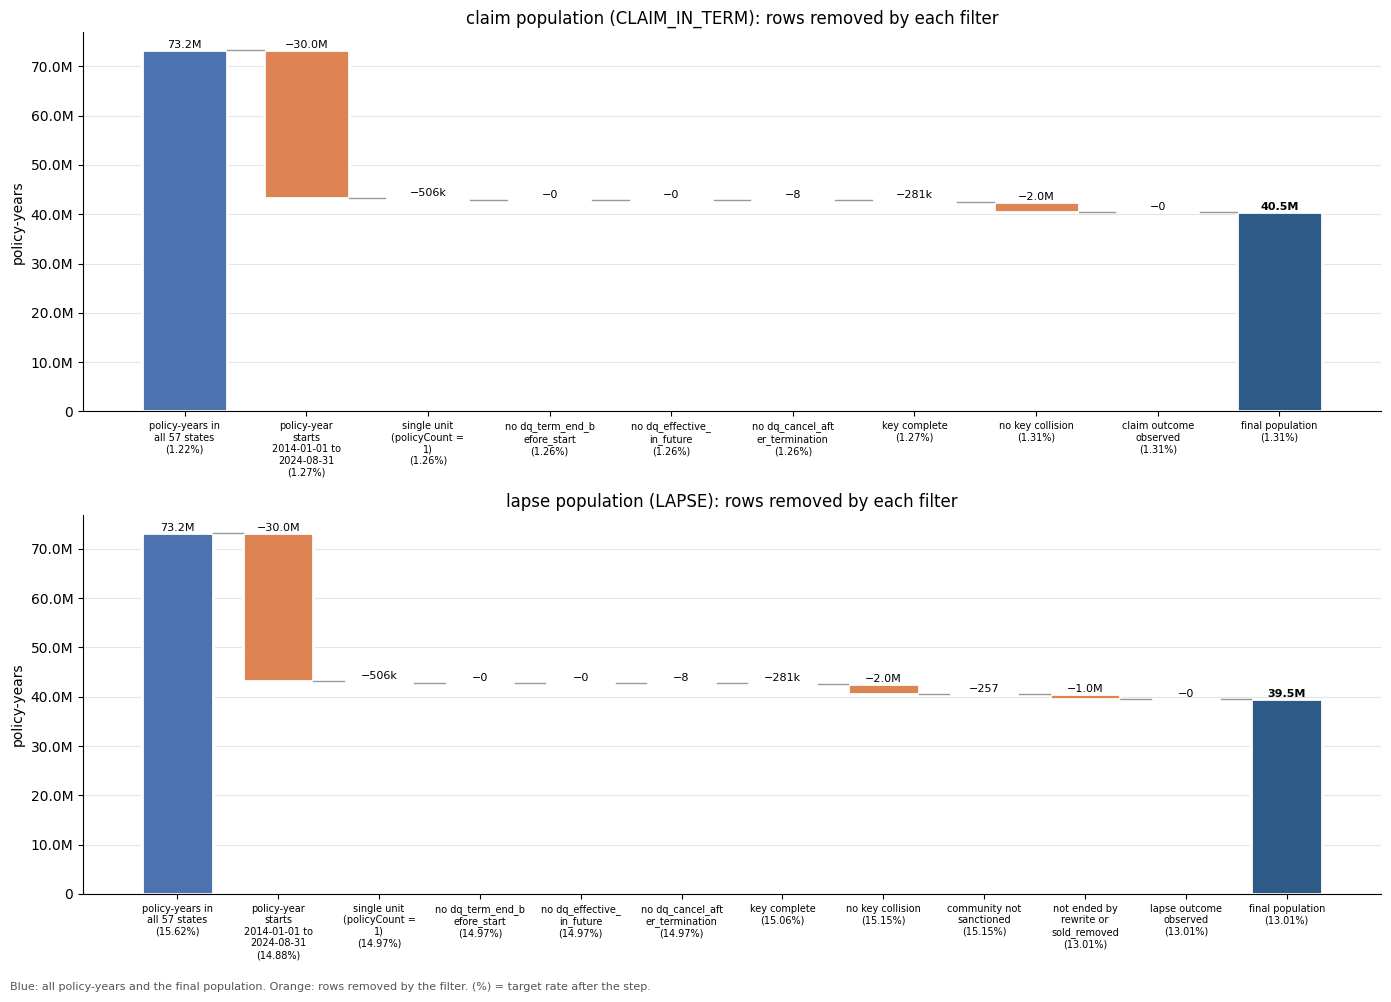

In [15]:
# Step 3.4b Waterfall charts: rows removed by each filter, and the target rate after it
import textwrap
from matplotlib.ticker import FuncFormatter

def short(n):
    '''40,847,887 -> "40.8M", 455,595 -> "456k", 7 -> "7".'''
    n = abs(n)
    return f"{n / 1e6:.1f}M" if n >= 1e6 else f"{n / 1e3:.0f}k" if n >= 1e3 else f"{n:,.0f}"

def plot_waterfall(wf, key, ax):
    '''One population: start bar, one floating bar per filter (rows removed), final bar.'''
    n = len(wf)
    x = list(range(n + 1))                                    # every step, plus the final population
    heights = [wf["rows_left"].iloc[0], *wf["rows_removed"].iloc[1:], wf["rows_left"].iloc[-1]]
    bottoms = [0, *wf["rows_left"].iloc[1:], 0]
    colors = ["#4C72B0", *["#DD8452"] * (n - 1), "#2E5A88"]
    ax.bar(x, heights, bottom=bottoms, color=colors, width=0.7, edgecolor="white", linewidth=2)

    # thin connectors: the level carried from one bar to the next
    for i in range(n):
        level = wf["rows_left"].iloc[i]
        ax.plot([i + 0.35, i + 0.65], [level, level], color="#999999", linewidth=1)

    # values: total at the start and end, rows removed on each filter
    ax.text(0, heights[0], short(heights[0]), ha="center", va="bottom", fontsize=8)
    for i in range(1, n):
        ax.text(i, wf["rows_left"].iloc[i - 1], f"−{short(heights[i])}", ha="center", va="bottom", fontsize=8)
    ax.text(n, heights[-1], short(heights[-1]), ha="center", va="bottom", fontsize=8, fontweight="bold")

    # x labels: the filter, and the target rate after it
    labels = [f"{textwrap.fill(f, 16)}\n({r:.2f}%)" if pd.notna(r) else textwrap.fill(f, 16)
              for f, r in zip(wf["filter"], wf["positive_pct"])]
    labels.append(f"final population\n({wf['positive_pct'].iloc[-1]:.2f}%)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=7)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: short(v)))
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set(title=f"{key} population ({TARGETS[key]}): rows removed by each filter",
           ylabel="policy-years")

fig, axes = plt.subplots(len(waterfalls), 1, figsize=(14, 5 * len(waterfalls)))
for ax, (key, wf) in zip(axes, waterfalls.items()):
    plot_waterfall(wf, key, ax)
fig.text(0.01, 0.005, "Blue: all policy-years and the final population. Orange: rows removed by the filter. "
                      "(%) = target rate after the step.", fontsize=8, color="#555555")
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig(REPORTS / "fig_population_waterfall.png", dpi=150)
plt.show()

### Section 4. Sampling strategy

#### 4.1 Decide whether to sample
If a training set is too large for memory, we keep every positive case and a fixed share of the negatives. Each kept negative gets the weight `1 / NEG_RATE`, so weighted rates and calibration match the full data. We only sample the **training** split: validation and test stay complete, so our evaluation in notebook 08 is unbiased.

As a rule of thumb, a pandas table needs about 8 bytes per value. We estimate the memory with 80 feature columns.

**Our decision: no sampling.**
- **Compact types:** numbers as `float32` (4 bytes) and codes as `category`, which roughly halves the memory.
- **Load only what a model needs:** one population and its feature columns at a time.
- **Gradient boosting (07):** LightGBM bins each feature into at most 255 values (1 byte each) when it builds its dataset, so 29M × 80 needs about 2–3 GB once built.
- **Logistic regression (06):** we train in batches read from the Parquet file (`SGDClassifier.partial_fit`), or on a fixed random subset for tuning only, never for the final fit.

DuckDB queries (notebook 05 EDA, this notebook) are not limited by memory: they spill to disk.

In [16]:
# Step 4.1 Training size per population, before and after sampling
train_years = ", ".join(str(y) for y in SPLIT_YEARS["train"])
N_FEATURES = 80
rows = []
for key, steps in STEPS.items():
    t = TARGETS[key]
    n, pos = con.execute(f'''SELECT COUNT(*), SUM({t}) FROM pop_base
                             WHERE {all_of(steps)} AND period_year IN ({train_years})''').fetchall()[0]
    pos = pos or 0
    kept = pos + (n - pos) * NEG_RATE[key]
    rows.append({"population": key, "train_rows": n, "positives": pos,
                 "neg_rate": NEG_RATE[key], "rows_after_sampling": int(kept),
                 "approx_gb_full": round(n * N_FEATURES * 8 / 1e9, 1),
                 "approx_gb_sampled": round(kept * N_FEATURES * 8 / 1e9, 1)})
pd.DataFrame(rows)

,population,train_rows,positives,neg_rate,rows_after_sampling,approx_gb_full,approx_gb_sampled
0,claim,27496820,357822,1.0,27496820,17.6,17.6
1,lapse,26758825,3703225,1.0,26758825,17.1,17.1


### Section 5. Time-based split
We train on the past and test on the future, the way the model would be used.

#### 5.1 Train, test and validation periods
We assign each policy-year to a split by the year it starts: train (2014–2020), then **test** (2021–2022, to tune and compare models), then **validation** (2023 to August 2024, our final holdout, used once). Nothing from a later period appears in an earlier one.

The same house can appear in train (2020) and validation (2023). That is intended: the model scores every policy again each year, like a credit model re-scoring a customer. What must not happen is a feature that uses information from after the policy-year starts; we check that in notebook 05.

In [17]:
# Step 5.1 The population view: split, population flags, sample flags and weights
split_sql = split_case("period_year", SPLIT_YEARS)
pop_cols = []
for key, steps in STEPS.items():
    t = TARGETS[key]
    rate = NEG_RATE[key]
    pop_cols += [
        f"({all_of(steps)}) AS in_pop_{key}",
        f"(({all_of(steps)}) AND ({split_sql} <> 'train' OR {t} = 1 OR {sample_condition('period_id', rate, SEED)})) AS sample_{key}",
        f"CASE WHEN {split_sql} = 'train' AND {t} = 0 THEN {1 / rate if rate > 0 else 0} ELSE 1.0 END AS weight_{key}",
    ]

con.execute(f'''
CREATE OR REPLACE VIEW population AS
SELECT *, {split_sql} AS split,
       {", ".join(pop_cols)}
FROM pop_base
''')
con.sql('''
    SELECT split, COUNT(*) AS policy_years,
           COUNT(*) FILTER (WHERE in_pop_claim) AS claim_pop,
           COUNT(*) FILTER (WHERE in_pop_lapse) AS lapse_pop
    FROM population GROUP BY 1 ORDER BY 1
''').df()

,split,policy_years,claim_pop,lapse_pop
0,test,7781362,7275717,7105637
1,train,29366492,27496820,26758825
2,valid,7372313,5724790,5621274
3,None,28728137,0,0


#### 5.2 Rolling-origin folds
We train up to year t and test on t+1, for several t. This shows how stable the results are across storm years and calm years, instead of trusting a single test year.

We build the folds only from the training and test years (2014–2022), so our final holdout (validation, 2023–2024) is never used for tuning. Each fold trains on at least 3 years.

In [18]:
# Step 5.2a The folds: training and tuning years only, so the final holdout stays unseen
TUNING_YEARS = (YEARS[0], max(SPLIT_YEARS[TUNING_SPLIT]))
folds = rolling_folds(TUNING_YEARS, min_train_years=3)
folds

,fold,train_from,train_to,test_year
0,1,2014,2016,2017
1,2,2014,2017,2018
2,3,2014,2018,2019
3,4,2014,2019,2020
4,5,2014,2020,2021
5,6,2014,2021,2022


In [19]:
# Step 5.2b Size and claim rate of each fold's train and test years (claim population)
fold_rows = []
for f in folds.itertuples():
    for role, cond in [("fold train", f"period_year BETWEEN {f.train_from} AND {f.train_to}"),
                       ("fold check", f"period_year = {f.test_year}")]:
        n, rate = con.execute(f'''SELECT COUNT(*), ROUND(100 * AVG(CLAIM_IN_TERM), 3)
                                  FROM population WHERE in_pop_claim AND {cond}''').fetchall()[0]
        fold_rows.append({"fold": f.fold, "role": role, "years": cond.split(" ", 1)[1], "rows": n, "claim_pct": rate})
pd.DataFrame(fold_rows)

,fold,role,years,rows,claim_pct
0,1,fold train,BETWEEN 2014 AND 2016,11897269,1.297
1,1,fold check,= 2017,3897036,2.677
2,2,fold train,BETWEEN 2014 AND 2017,15794305,1.638
3,2,fold check,= 2018,3928357,0.953
4,3,fold train,BETWEEN 2014 AND 2018,19722662,1.501
5,3,fold check,= 2019,3899882,0.687
6,4,fold train,BETWEEN 2014 AND 2019,23622544,1.367
7,4,fold check,= 2020,3874276,0.902
8,5,fold train,BETWEEN 2014 AND 2020,27496820,1.301
9,5,fold check,= 2021,3752555,0.997


### Section 6. Check the split

#### 6.1 Target rates and sizes per split
We compare the row counts and target rates in each split, and explain any big differences (for example a storm year in one split only). `weighted_rate_pct` is the rate in the sample after applying the weights; it must match `rate_pct`, otherwise the weights are wrong.

In [20]:
# Step 6.1a One table per population
split_summary = {}
for key in STEPS:
    split_summary[key] = con.sql(split_summary_sql("population", key)).df()
    print(f"\n{key} ({TARGETS[key]})")
    display(split_summary[key])


claim (CLAIM_IN_TERM)


,split,rows,positives,rate_pct,sampled_rows,weighted_rate_pct
0,test,7275717,83603.0,1.149,7275717,1.149
1,train,27496820,357822.0,1.301,27496820,1.301
2,valid,5724790,89516.0,1.564,5724790,1.564



lapse (LAPSE)


,split,rows,positives,rate_pct,sampled_rows,weighted_rate_pct
0,test,7105637,854084.0,12.020,7105637,12.020
1,train,26758825,3703225.0,13.839,26758825,13.839
2,valid,5621274,578846.0,10.297,5621274,10.297


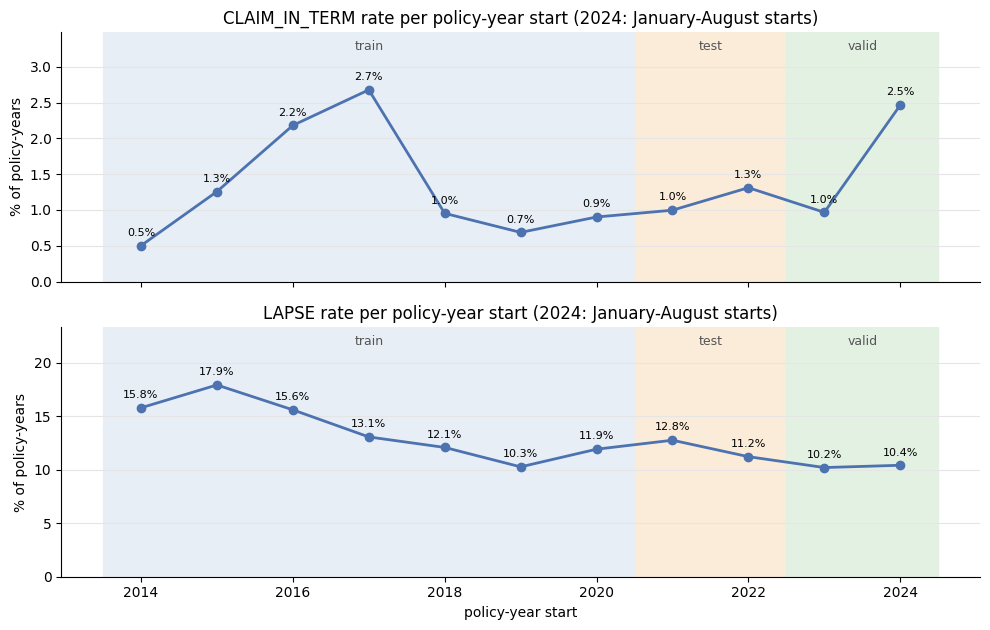

claim           lapse         
             split rate_pct  split rate_pct
period_year                                
2014         train    0.502  train   15.801
2015         train    1.257  train   17.937
2016         train    2.181  train   15.610
2017         train    2.677  train   13.077
2018         train    0.953  train   12.094
2019         train    0.687  train   10.277
2020         train    0.902  train   11.929
2021          test    0.997   test   12.769
2022          test    1.311   test   11.229
2023         valid    0.967  valid   10.212
2024         valid    2.464  valid   10.426

In [21]:
# Step 6.1b Target rate per year, one panel per population, with the splits shaded
by_year = {key: con.sql(split_summary_sql("population", key, ["split", "period_year"])).df()
                   .sort_values("period_year")                     # connect the points in time order
           for key in STEPS}

split_shade = {"train": "#E8EEF6", TUNING_SPLIT: "#FBEBD9", HOLDOUT_SPLIT: "#E3F1E3"}
fig, axes = plt.subplots(len(by_year), 1, figsize=(10, 3.2 * len(by_year)), sharex=True)
for ax, (key, df) in zip(axes, by_year.items()):
    for name, years in SPLIT_YEARS.items():
        ax.axvspan(min(years) - 0.5, max(years) + 0.5, color=split_shade[name], zorder=0)
        ax.text((min(years) + max(years)) / 2, 0.97, name, transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=9, color="#555555")
    ax.plot(df["period_year"], df["rate_pct"], marker="o", color="#4C72B0", linewidth=2)
    for x, y in zip(df["period_year"], df["rate_pct"]):
        ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_ylim(0, df["rate_pct"].max() * 1.3)
    ax.set(ylabel="% of policy-years", title=f"{TARGETS[key]} rate per policy-year start (2024: January-August starts)")
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[-1].set_xlabel("policy-year start")
axes[-1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig(REPORTS / "fig_target_rates_by_split.png", dpi=150)
plt.show()

pd.concat({k: df.set_index("period_year")[["split", "rate_pct"]] for k, df in by_year.items()}, axis=1)

In [22]:
# Step 6.1c Every population row is in exactly one split, and the splits follow each other in time
con.sql(f'''
    SELECT COUNT(*) FILTER (WHERE (in_pop_claim OR in_pop_lapse) AND split IS NULL) AS pop_rows_without_split,
           COUNT(DISTINCT period_year) FILTER (WHERE split = 'train') AS train_years,
           MAX(period_year) FILTER (WHERE split = 'train') < MIN(period_year) FILTER (WHERE split = '{TUNING_SPLIT}')
               AND MAX(period_year) FILTER (WHERE split = '{TUNING_SPLIT}') < MIN(period_year) FILTER (WHERE split = '{HOLDOUT_SPLIT}')
               AS time_order_ok
    FROM population
''').df()

,pop_rows_without_split,train_years,time_order_ok
0,0,7,True


> **Our findings:**
>
> - **Sizes.** The claim population has 27,496,820 policy-years in train, 7,275,717 in test and 5,724,790 in validation (67.9%, 18.0% and 14.1% of the 40,497,327 total); the lapse population 26,758,825, 7,105,637 and 5,621,274 (67.8%, 18.0% and 14.2% of 39,485,736). Train is large enough that we keep every row (Section 4.1), and test and validation each hold millions of rows, so their rates are precise.
> - **No sampling, so the weights do nothing.** `weighted_rate_pct` equals `rate_pct` in every split, as expected with `NEG_RATE` = 1.0.
> - **The claim rate depends on which storms fall in each split.** Train has 1.30% (357,822 claims), including the two strongest years of our window, 2016 (2.18%; Louisiana floods, Matthew) and 2017 (2.68%; Harvey, Irma). Test has 1.15% (83,603 claims), with Ian in 2022 (1.31%) next to a calmer 2021 (1.00%). Validation has 1.56% (89,516 claims): the calm 2023 (0.97%) and January–August 2024 (2.46%), which covers Debby, Helene and Milton. So each split has storm and calm years, and the model is never judged only on a calm period or only on a storm.
> - **The 2024 claim rate (2.46%) is high partly by design:** every policy-year starting January–August 2024 covers the whole 2024 hurricane season (Step 2.3b). It is a fair test, since each row is scored against its own outcome, but it is not a calendar-year rate.
> - **The lapse rate falls over time: 13.84% in train, 12.02% in test and 10.30% in validation.** Lapse was highest in 2014–2016 (15.6–17.9%) and has been about 10–13% since 2018 (10.21% in 2023, 10.43% in 2024). A model fitted on train will tend to predict too much lapse in the later years. We will check this with calibration on the test split (notebooks 06–07), and recalibrate on it if needed, before the final check on validation.
> - **The splits follow each other in time (6.1c):** every population row has a split (`pop_rows_without_split` = 0), train covers 7 years, and `time_order_ok` is True. Our 6 tuning folds (5.2) check each year from 2017 to 2022 and never use the validation years.

### Section 7. Export

#### 7.1 Save the population and split assignments
We save one row per policy-year that is in at least one population. Notebook 05 starts from this file and joins the features from `policies_clean` by `id`.

| Column | Meaning |
|---|---|
| `period_id`, `id`, `period_no`, `policy_key` | the policy-year, its term and its rebuilt policy |
| `propertyState`, `period_year`, `period_start`, `period_end`, `exposure` | where and when |
| `split` | `train`, `valid` or `test` |
| `in_pop_claim`, `in_pop_lapse` | which populations the row belongs to |
| `sample_<population>`, `weight_<population>` | rows to use for training, and their weights |
| `CLAIM_IN_TERM`, `LAPSE` | the targets of our two models |
| `CLAIM_PAID_IN_TERM`, `CANCEL_IN_TERM`, `NON_RENEWAL`, `SOLD_REMOVED_IN_TERM` | alternative and component targets, to see which part of `LAPSE` drives a finding |
| `claim_count`, `claim_paid_total` | claims in the policy-year, for the severity model (**target-only**) |
| `term_no`, `n_terms_key`, `dq_key_collision`, `community_sanctioned`, `policy_count`, `occupancyType` | context for checks |

In [23]:
# Step 7.1 Export
keep = ["period_id", "id", "period_no", "policy_key", "propertyState", "period_year", "period_start", "period_end",
        "exposure", "split",
        *[f"{p}_{k}" for k in STEPS for p in ("in_pop", "sample", "weight")],
        "CLAIM_IN_TERM", "LAPSE", "CLAIM_PAID_IN_TERM", "CANCEL_IN_TERM", "NON_RENEWAL", "SOLD_REMOVED_IN_TERM",
        "claim_count", "claim_paid_total",
        "term_no", "n_terms_key", "dq_key_collision", "community_sanctioned", "policy_count", "occupancyType"]

OUT = PROCESSED / "modeling_population.parquet"
con.execute(f'''
    COPY (SELECT {", ".join(keep)} FROM population
          WHERE in_pop_claim OR in_pop_lapse)
    TO '{OUT}' (FORMAT PARQUET, COMPRESSION ZSTD)
''')
n_out = scalar(con, f"SELECT COUNT(*) FROM read_parquet('{OUT}')")
print(f"saved {OUT.name}: {n_out:,} rows")

saved modeling_population.parquet: 40,497,327 rows


#### 7.2 Save the waterfall, split summary and folds
We save every table from this notebook as a CSV, plus one Excel workbook with a sheet per table.

In [24]:
# Step 7.2a Log the population decisions
for key, wf in waterfalls.items():
    for r in wf.iloc[1:].itertuples():
        log.add(f"population_{key}", "-", r.filter, f"filter {r.step} of the {key} population", int(r.rows_removed))
    t = TARGETS[key]
    sampled_out = scalar(con, f"SELECT COUNT(*) FROM population WHERE in_pop_{key} AND NOT sample_{key}")
    log.add(f"population_{key}", t, f"sample training negatives at {NEG_RATE[key]}",
            f"weight 1/{NEG_RATE[key]} keeps rates unbiased; valid and test not sampled", sampled_out)
population_log = log.to_frame()
population_log

,table,column,rule,reason,rows_affected
0,population_claim,-,policy-year starts 2014-01-01 to 2024-08-31,filter 2 of the claim population,29952965
1,population_claim,-,single unit (policyCount = 1),filter 3 of the claim population,506381
2,population_claim,-,no dq_term_end_before_start,filter 4 of the claim population,0
3,population_claim,-,no dq_effective_in_future,filter 5 of the claim population,0
4,population_claim,-,no dq_cancel_after_termination,filter 6 of the claim population,8
5,population_claim,-,key complete,filter 7 of the claim population,281212
6,population_claim,-,no key collision,filter 8 of the claim population,2010411
7,population_claim,-,claim outcome observed,filter 9 of the claim population,0
8,population_claim,CLAIM_IN_TERM,sample training negatives at 1.0,weight 1/1.0 keeps rates unbiased; valid and t...,0
9,population_lapse,-,policy-year starts 2014-01-01 to 2024-08-31,filter 2 of the lapse population,29952965


In [25]:
# Step 7.2b Reports
outputs = {"population_log.csv": population_log, "population_folds.csv": folds,
           "population_dq_counts.csv": dq_counts.reset_index(names="flag"),
           "population_label_maturity.csv": maturity}
for key in STEPS:
    outputs[f"population_waterfall_{key}.csv"] = waterfalls[key]
    outputs[f"population_split_{key}.csv"] = split_summary[key]
    outputs[f"population_split_year_{key}.csv"] = by_year[key]

for name, df in outputs.items():
    df.to_csv(REPORTS / name, index=False)
    print("saved", name)

with pd.ExcelWriter(REPORTS / "modeling_population_report.xlsx") as xw:
    for name, df in outputs.items():
        df.to_excel(xw, sheet_name=name.removesuffix(".csv").replace("population_", "")[:31], index=False)

saved population_log.csv
saved population_folds.csv
saved population_dq_counts.csv
saved population_label_maturity.csv
saved population_waterfall_claim.csv
saved population_split_claim.csv
saved population_split_year_claim.csv
saved population_waterfall_lapse.csv
saved population_split_lapse.csv
saved population_split_year_lapse.csv


#### 7.3 Population decisions note
We write a short markdown file in `docs/`, like our notes for notebooks 02 and 03. We fill in the `...` lines before submitting.

In [26]:
# Step 7.3 Population decisions note
final = {k: wf.iloc[-1] for k, wf in waterfalls.items()}
note = f'''# Modeling population and split decisions (notebook 04)

## Summary
- Scope: all {len(SCOPE_STATES)} states, policy-years starting {YEARS[0]}-01-01 to {LAST_START} (data cutoff {CUTOFF}).
- Split: {"; ".join(f"{k} {min(v)}-{max(v)}" if len(v) > 1 else f"{k} {v[0]}" for k, v in SPLIT_YEARS.items())}.
- Claim population: {final["claim"]["rows_left"]:,} policy-years, {final["claim"]["positive_pct"]}% with a claim.
- Lapse population: {final["lapse"]["rows_left"]:,} policy-years, {final["lapse"]["positive_pct"]}% lapsed (cancelled for a lapse reason or not renewed).
- Sampling: none (NEG_RATE {NEG_RATE}); every policy-year in the populations is kept.
- Naming: we tune on '{TUNING_SPLIT}' and keep '{HOLDOUT_SPLIT}' as the final holdout, used once.
- Rolling-origin folds: {len(folds)} (train from {YEARS[0]} up to year t, check on t+1; holdout years never used).

## Key decisions
<!-- Write 1-2 sentences for each: what we decided and why -->
- **Scope (states and years):** ...
- **Multi-unit rows:** ...
- **dq_ flags excluded:** {", ".join(DQ_EXCLUDE) or "none"}. ...
- **Key collisions:** ...
- **Rewrites and sales in the lapse population:** ...
- **Lapse target:** `LAPSE` combines `CANCEL_IN_TERM` and `NON_RENEWAL` (one lapse model, as in our README). ...
- **Sampling:** ...

## Left for later notebooks
- Notebook 05: features from `policies_clean` joined by `id`; every fitted step (missing values, encoding) uses the training split only.
- Notebooks 06-07: train on `sample_<population>` rows with `weight_<population>`; tune on the '{TUNING_SPLIT}' rows.
- Notebook 08: final results on the '{HOLDOUT_SPLIT}' rows, used once.
'''
(DOCS / "population_decisions.md").write_text(note)
print(note)

# Modeling population and split decisions (notebook 04)

## Summary
- Scope: all 57 states, policy-years starting 2014-01-01 to 2024-08-31 (data cutoff 2026-09-08).
- Split: train 2014-2020; test 2021-2022; valid 2023-2024.
- Claim population: 40,497,327 policy-years, 1.311% with a claim.
- Lapse population: 39,485,736 policy-years, 13.008% lapsed (cancelled for a lapse reason or not renewed).
- Sampling: none (NEG_RATE {'claim': 1.0, 'lapse': 1.0}); every policy-year in the populations is kept.
- Naming: we tune on 'test' and keep 'valid' as the final holdout, used once.
- Rolling-origin folds: 6 (train from 2014 up to year t, check on t+1; holdout years never used).

## Key decisions
<!-- Write 1-2 sentences for each: what we decided and why -->
- **Scope (states and years):** ...
- **Multi-unit rows:** ...
- **dq_ flags excluded:** dq_term_end_before_start, dq_effective_in_future, dq_cancel_after_termination. ...
- **Key collisions:** ...
- **Rewrites and sales in the lapse populati